In [8]:
%pip install pygad

  Using cached pygad-3.7.0-py3-none-any.whl.metadata (18 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached pygad-3.7.0-py3-none-any.whl (218 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   -------------------- ------------------- 1/2 [pygad]
   -------------------- ------------------- 1/2 [pygad]
   ---------------------------------------- 2/2 [pygad]

Note: you may need to restart the kernel to use updated packages.


TODO 
1. Choose other initial guesses and give noo. of iterations
2. Explain the time and no of iteration difference for the both method of optimisation i.e. scipy and pygad

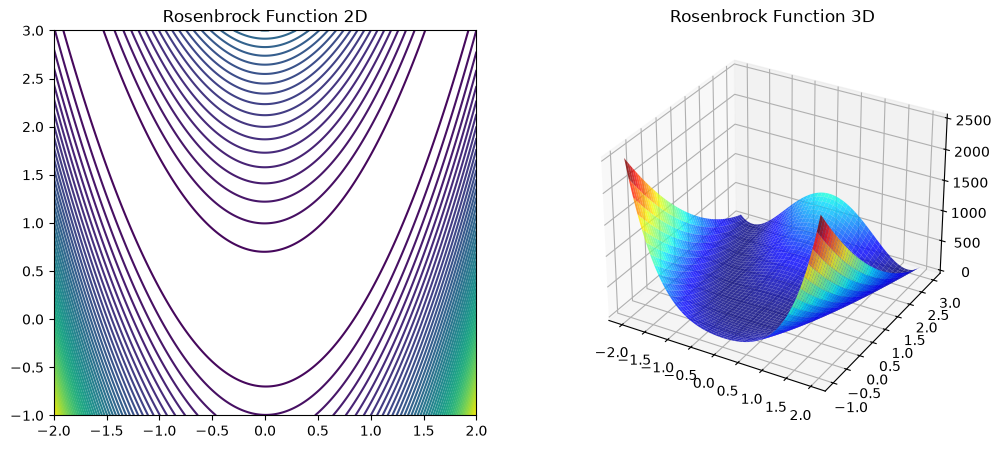

Initial guess [-3, 1], Result: [0.99999552 0.99999104], Value: 2.0053708164599e-11, Success: True, Iterations: 59, Time: 0.0423 sec
Initial guess [1.5, 2], Result: [0.99999506 0.99999011], Value: 2.4408994262766184e-11, Success: True, Iterations: 17, Time: 0.0122 sec
Initial guess [5, 0], Result: [0.99999548 0.99999095], Value: 2.0451985797724782e-11, Success: True, Iterations: 68, Time: 0.0475 sec


c:\Users\pc\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-3, 1], Solution: [1.01843443 1.03737746], Value: rosenbrock(solution), iterations: 2000, Time: 2.4312 sec


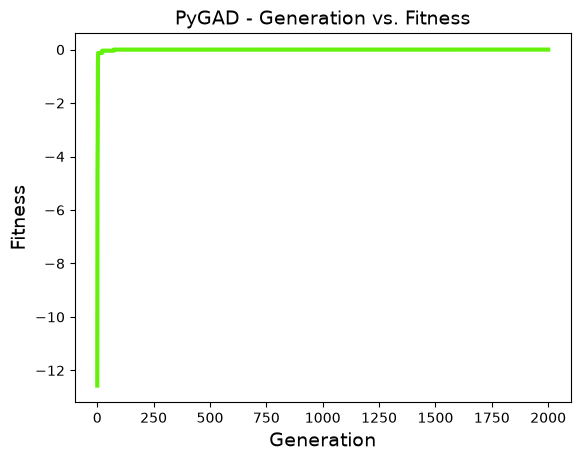

PyGAD initial guess [1.5, 2], Solution: [0.99429147 0.98895731], Value: rosenbrock(solution), iterations: 2000, Time: 2.2949 sec


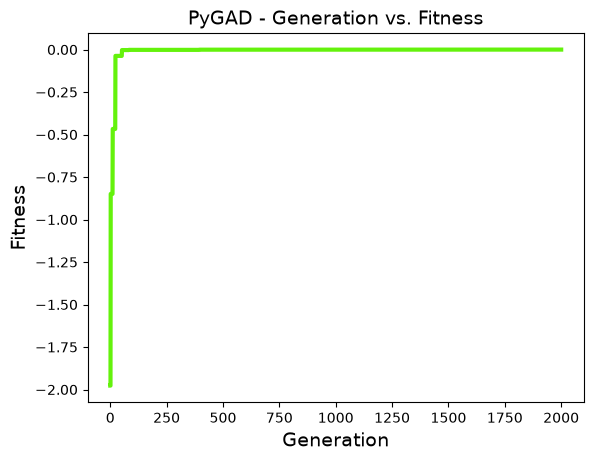

PyGAD initial guess [5, 0], Solution: [0.98757211 0.97589909], Value: rosenbrock(solution), iterations: 2000, Time: 1.8512 sec


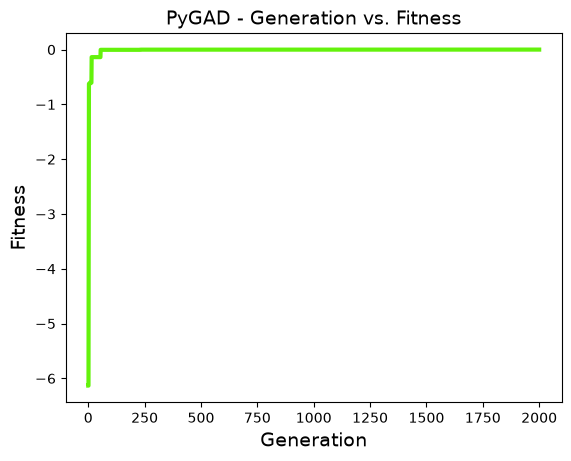

In [16]:
import numpy as np
import time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize
import pygad

# Define Rosenbrock function
def rosenbrock(x):
    return (1 - x[0])**2 + 100 * (x[1] - x[0]**2)**2

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = rosenbrock([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Rosenbrock Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Rosenbrock Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization
init_guesses = [[-3, 1], [1.5, 2], [5, 0]]
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(rosenbrock, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -rosenbrock(solution) # pygad maximizes, so negate

elapsed_time = []
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: rosenbrock(solution), iterations: {iters}, Time: {elapsed_time:.4f} sec")
    #Uncomment to plot fitness:
    ga_instance.plot_fitness()

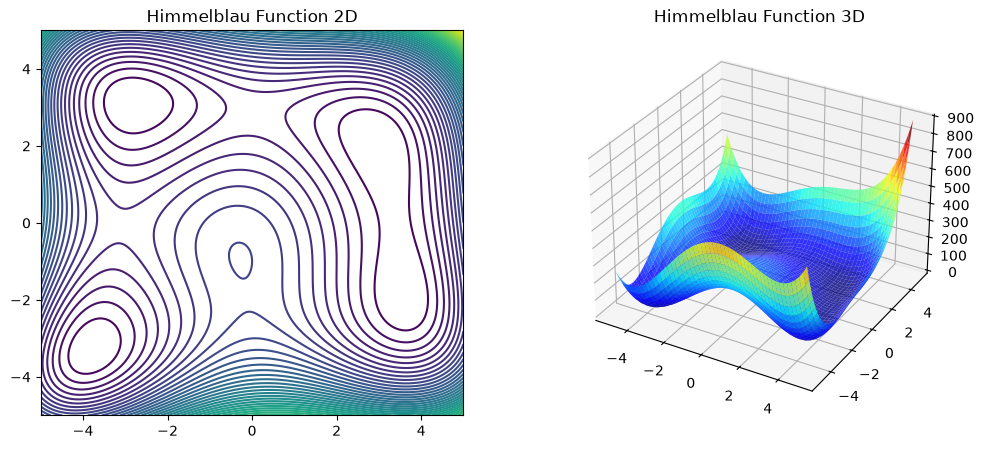

Initial guess [5, 4.5], Result: [3.00000001 2.00000001], Value: 8.672187257734313e-15, Success: True, Iterations: 15, Time: 2.0779 sec
Initial guess [2, 3], Result: [2.99999999 1.99999997], Value: 2.492888014791407e-14, Success: True, Iterations: 8, Time: 2.0779 sec
Initial guess [1.5, 1.5], Result: [2.99999999 2.        ], Value: 2.4142979934273736e-15, Success: True, Iterations: 9, Time: 2.0779 sec


c:\Users\pc\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [5, 4.5], Solution: [ 3.58982011 -1.84930058], Value: 0.0015015637238354625, iterations: 2000, Time: 2.0779 sec
PyGAD initial guess [2, 3], Solution: [ 3.57987852 -1.84509274], Value: 0.0011221383130866453, iterations: 2000, Time: 2.0779 sec
PyGAD initial guess [1.5, 1.5], Solution: [ 3.58200168 -1.84247884], Value: 0.0006793880969023173, iterations: 2000, Time: 2.0779 sec


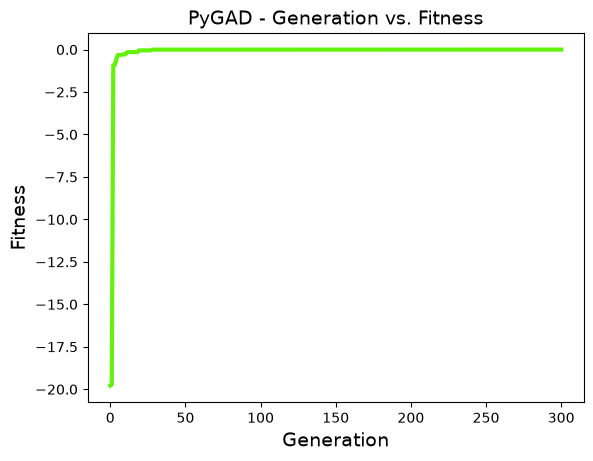

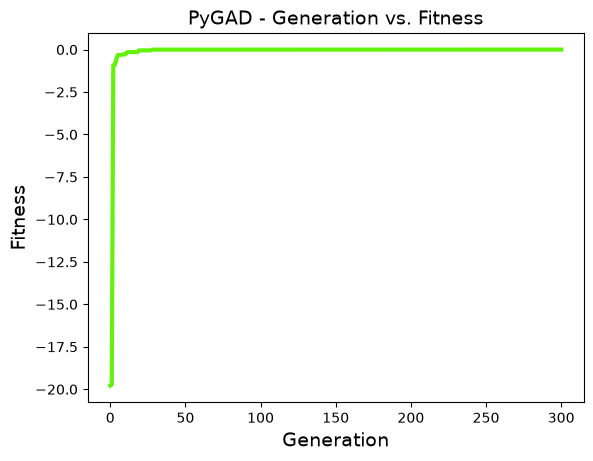

In [14]:
def himmelblau(x):
    x = np.asarray(x) # Convert to numpy array
    return (x[0]**2 + x[1] - 11)**2 + (x[0] + x[1]**2 - 7)**2

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")
plt.show()

# Scipy Optimization
init_guesses = [[5, 4.5], [2, 3], [1.5, 1.5]]
for guess in init_guesses:
    result = minimize(himmelblau, guess, method='BFGS')
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec") # TODO include time taken

# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)
for guess in init_guesses:
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low':-5, 'high':5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}, iterations: {iters}, Time: {elapsed_time:.4f} sec") # TODO include iterations and time taken
ga_instance.plot_fitness()

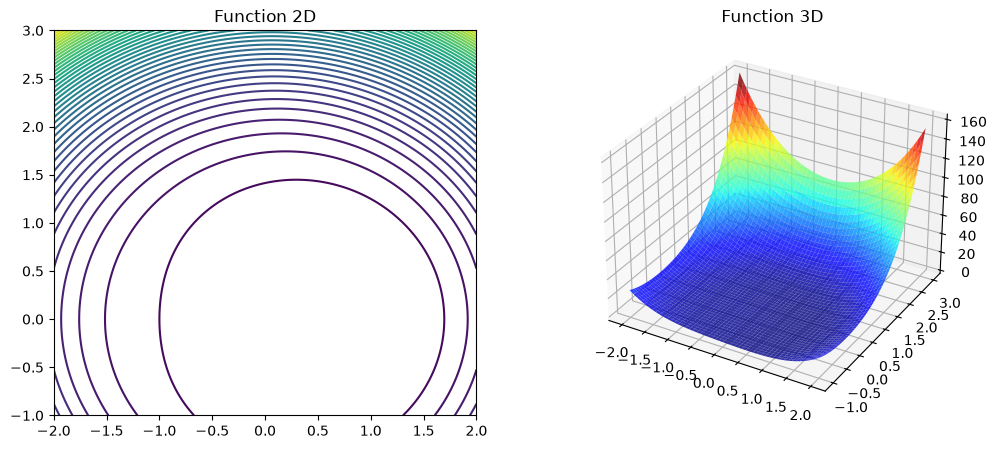

Initial guess [-3, 1], Result: [ 9.99999982e-01 -2.33982596e-08], Value: 2.209061276051743e-15, Success: True, Iterations: 16, Time: 0.0085 sec
Initial guess [1.5, 2], Result: [9.99999959e-01 6.62851602e-08], Value: 1.259820803758452e-14, Success: True, Iterations: 11, Time: 0.0080 sec
Initial guess [5, 0], Result: [1.00000001e+00 3.72027113e-07], Value: 1.3871769008312376e-13, Success: True, Iterations: 11, Time: 0.0039 sec


c:\Users\pc\miniconda3\envs\mude-base\Lib\site-packages\pygad\utils\validation.py:966: UserWarning: The percentage of genes to mutate (mutation_percent_genes=10) resulted in selecting (0) genes. The number of genes to mutate is set to 1 (mutation_num_genes=1).
If you do not want to mutate any gene, please set mutation_type=None.
  warnings.warn(


PyGAD initial guess [-3, 1], Solution: [9.99523086e-01 2.25280365e-04], Value: func_1(solution), iterations: 2000, Time: 2.4519 sec


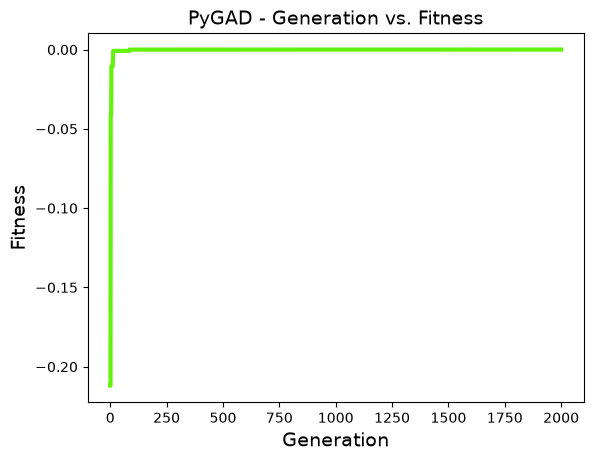

PyGAD initial guess [1.5, 2], Solution: [ 1.00045730e+00 -2.26519474e-05], Value: func_1(solution), iterations: 2000, Time: 2.1264 sec


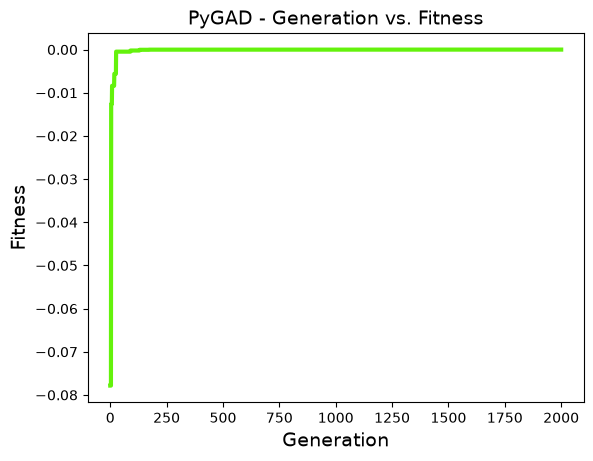

PyGAD initial guess [5, 0], Solution: [ 1.00261227e+00 -1.93736745e-04], Value: func_1(solution), iterations: 2000, Time: 2.4444 sec


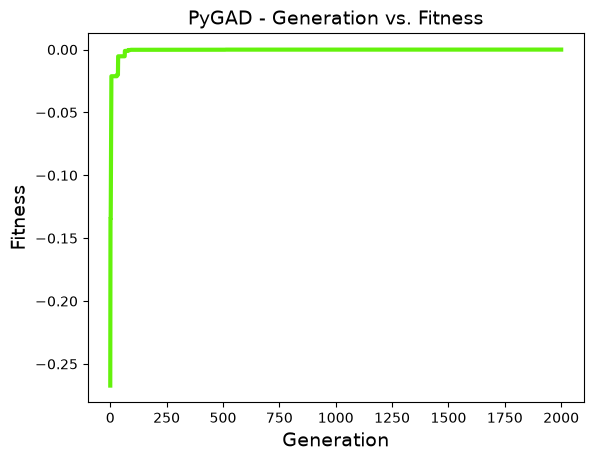

In [18]:
# Define Rosenbrock function
def func_1(x):
    return ((x[0]**2 + x[1]**2 -1)**2 + (x[0] - 1)**2 +x[1]**2)

# 2D & 3D plots
x_range = np.linspace(-2, 2, 400)
y_range = np.linspace(-1, 3, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = func_1([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Function 3D")
plt.show()

elapsed_time = []
# Scipy Optimization
init_guesses = [[-3, 1], [1.5, 2], [5, 0]]
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    result = minimize(func_1, guess, method='BFGS')
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}, Time: {elapsed_time:.4f} sec")

# PyGAD Optimization
def fitness_func(ga_instance, solution, solution_idx):
    return -func_1(solution) # pygad maximizes, so negate

elapsed_time = []
for guess in init_guesses:
    start_time = time.perf_counter()   # start timer
    ga_instance = pygad.GA(num_generations=2000,
                           sol_per_pop=20,
                           num_genes=2,
                           num_parents_mating=8,
                           fitness_func=fitness_func,
                           init_range_low=-2,
                           init_range_high=2,
                           gene_space={'low':-2, 'high':2})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    iters = ga_instance.generations_completed
    end_time = time.perf_counter()     # end timer
    elapsed_time = end_time - start_time
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: func_1(solution), iterations: {iters}, Time: {elapsed_time:.4f} sec")
    #Uncomment to plot fitness:
    ga_instance.plot_fitness()